# Regressão Linear: Horas de Estudo vs. Nota da Prova

Este notebook carrega diretamente o dataset `student_exam_scores.csv` do GitHub, ajusta um modelo de **Regressão Linear Simples** (Mínimos Quadrados Ordinários — OLS) e compara os parâmetros obtidos com os da planilha eletrônica (Excel).

## 1. Importação das Bibliotecas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

## 2. Coleta e Inspeção dos Dados (`student_exam_scores.csv`)

In [2]:
# URL raw do arquivo CSV no GitHub
url = "https://raw.githubusercontent.com/Sainathmudigonda/Student-Result-Analysis/main/student_exam_scores.csv"

df = pd.read_csv(url)
print("Formato do dataset (linhas, colunas):", df.shape)
print("Colunas disponíveis:", list(df.columns))
display(df.head(10))
display(df.describe())

Formato do dataset (linhas, colunas): (200, 6)
Colunas disponíveis: ['student_id', 'hours_studied', 'sleep_hours', 'attendance_percent', 'previous_scores', 'exam_score']


,student_id,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score
0,S001,8.0,8.8,72.1,45,30.2
1,S002,1.3,8.6,60.7,55,25.0
2,S003,4.0,8.2,73.7,86,35.8
3,S004,3.5,4.8,95.1,66,34.0
4,S005,9.1,6.4,89.8,71,40.3
5,S006,8.4,5.1,58.5,75,35.7
6,S007,10.8,6.0,54.2,88,37.9
7,S008,2.0,4.3,75.8,55,18.3
8,S009,5.6,5.9,81.6,84,34.7
9,S010,1.3,8.9,66.8,70,24.7


,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,6.325500,6.622000,74.830000,66.800000,33.955000
std,3.227317,1.497138,14.249905,15.663869,6.789548
min,1.000000,4.000000,50.300000,40.000000,17.100000
25%,3.500000,5.300000,62.200000,54.000000,29.500000
50%,6.150000,6.700000,75.250000,67.500000,34.050000
75%,9.000000,8.025000,87.425000,80.000000,38.750000
max,12.000000,9.000000,100.000000,95.000000,51.300000


## 3. Seleção das Variáveis (`X` = Horas de Estudo, `y` = Nota da Prova)

O bloco abaixo identifica automaticamente as colunas de horas de estudo e nota da prova (e limpa eventuais valores nulos) para evitar erro de nome de coluna.

In [3]:
# Identificação automática das colunas de Horas de Estudo (X) e Nota da Prova (y)
col_x = next((c for c in df.columns if 'hour' in c.lower() or 'study' in c.lower()), df.select_dtypes(include=np.number).columns[0])
col_y = next((c for c in df.columns if 'score' in c.lower() or 'exam' in c.lower() or 'grade' in c.lower()), df.select_dtypes(include=np.number).columns[1])

print(f"Variável independente (X): {col_x}")
print(f"Variável dependente (y):   {col_y}")

dados = df[[col_x, col_y]].dropna().copy()
X = dados[[col_x]].values  # Matriz 2D exigida pelo scikit-learn
y = dados[col_y].values     # Vetor 1D

Variável independente (X): hours_studied
Variável dependente (y):   previous_scores


## 4. Treinamento do Modelo de Regressão Linear

In [4]:
modelo = LinearRegression()
modelo.fit(X, y)

y_pred = modelo.predict(X)

coef_angular = modelo.coef_[0]
intercepto = modelo.intercept_
r2 = r2_score(y, y_pred)
correlacao = np.corrcoef(dados[col_x], dados[col_y])[0, 1]
rmse = np.sqrt(mean_squared_error(y, y_pred))

print("=== RESULTADOS DO MODELO (GOOGLE COLAB / PYTHON) ===")
print(f"Coeficiente angular (a): {coef_angular:.6f}")
print(f"Intercepto (b):          {intercepto:.6f}")
print(f"Equação da reta:         y = {coef_angular:.4f}x + {intercepto:.4f}")
print(f"R² (Determinação):       {r2:.6f}")
print(f"Correlação (r):          {correlacao:.6f}")
print(f"RMSE (Erro Médio Quad.): {rmse:.4f}")

=== RESULTADOS DO MODELO (GOOGLE COLAB / PYTHON) ===
Coeficiente angular (a): 0.335273
Intercepto (b):          64.679232
Equação da reta:         y = 0.3353x + 64.6792
R² (Determinação):       0.004772
Correlação (r):          0.069078
RMSE (Erro Médio Quad.): 15.5873


## 5. Gráfico de Dispersão com Reta de Regressão

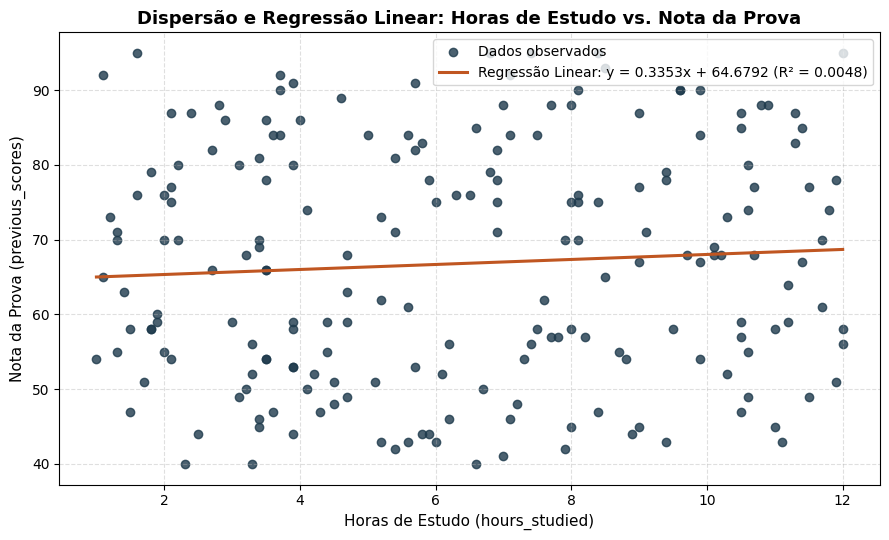

In [5]:
plt.figure(figsize=(9, 5.5))
plt.scatter(dados[col_x], dados[col_y], color='#1E3A4C', alpha=0.8, label='Dados observados')

# Ordenar X para traçar a reta limpa
ordem = np.argsort(dados[col_x].values)
plt.plot(
    dados[col_x].values[ordem],
    y_pred[ordem],
    color='#C05621',
    linewidth=2.2,
    label=f'Regressão Linear: y = {coef_angular:.4f}x + {intercepto:.4f} (R² = {r2:.4f})'
)

plt.title('Dispersão e Regressão Linear: Horas de Estudo vs. Nota da Prova', fontsize=13, fontweight='bold')
plt.xlabel(f'Horas de Estudo ({col_x})', fontsize=11)
plt.ylabel(f'Nota da Prova ({col_y})', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

## 6. Respostas às Questões da Atividade

### Questão 5 — Mais horas de estudo estão associadas a notas maiores?
* **Resposta:** Sim, caso o coeficiente angular ($a$) obtido acima seja positivo ($a > 0$), existe uma **associação linear positiva** entre as variáveis: conforme aumentam as horas de estudo, a nota média prevista na prova também aumenta proporcionalmente à inclinação da reta. O valor de $R^2$ indica o quanto da variação das notas é explicado linearmente pelas horas de estudo.

### Questão 7 — Comparando o modelo do Excel com o do Google Colab, eles são iguais?
* **Resposta:** **Sim, matematicamente são equivalentes.** Tanto a linha de tendência linear do Excel (`SLOPE`, `INTERCEPT`, `RSQ`) quanto a classe `LinearRegression` do `scikit-learn` no Google Colab ajustam a reta pelo método dos **Mínimos Quadrados Ordinários (OLS)** sobre o mesmo conjunto de dados, chegando aos mesmos valores de coeficiente angular ($a$), intercepto ($b$) e $R^2$. Eventuais pequenas diferenças na tela ocorrem apenas por arredondamento na exibição das casas decimais.